In [2]:
import os

os.chdir('..')

print("Current directory:", os.getcwd())

Current directory: /home/walter/projects/parkinson_disease


In [3]:
from src.visualization.visualizer import Visualizer, PlotType
from src.data.pahaw_dataset import PaHaWDataset
from src.visualization.vis_enum import PaHaWTasks, PaHaWFeatures
import pandas as pd
from src.preprocess.time_serie_to_image import TimeSerieToImage
from src.common.utils import load_svc_as_array, build_pahaw_mapping, load_ruamel, set_determinism
from src.preprocess.utils import generate_pahaw_paths, validate_experiments
from src.run.preprocess.run_preprocessing_to_image import RunPreprocessingToImage
from src.model.vanilla_cnn import VanillaCNN
from src.run.model.run_image_classifier import RunImageClassifier
from src.model.small_resnet_cnn import SmallResNetCNN

Patient 00097 has disease: H


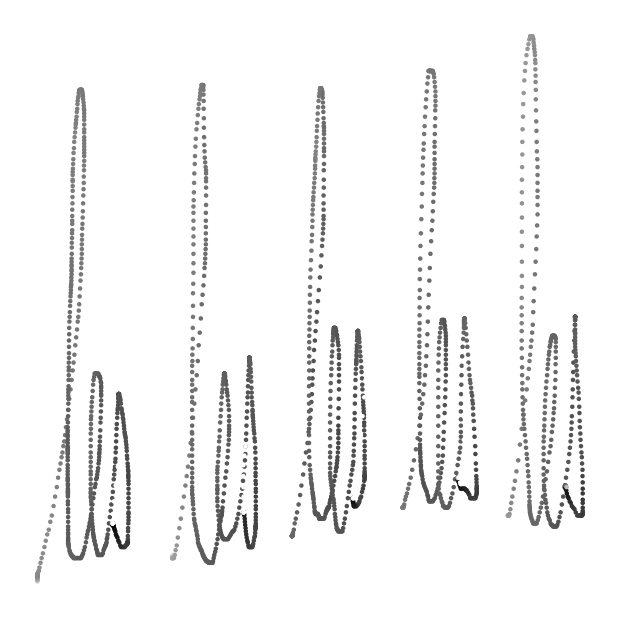

In [4]:
id = "00097"
task_idx = PaHaWTasks.TRIGRAM_LES.value
x_feature = PaHaWFeatures.X_COORDINATE.value
y_feature = PaHaWFeatures.Y_COORDINATE.value
z_feature = PaHaWFeatures.PRESSURE.value
base_dir = "data/PaHaW/PaHaW_public"
feature_names = [f.value for f in PaHaWFeatures]
mapping = build_pahaw_mapping(base_dir, feature_names)

vis = Visualizer()
df = pd.read_excel("data/PaHaW/PaHaW_files/corpus_PaHaW.xlsx", engine="openpyxl")

pahaw_dataset = PaHaWDataset(mapping, df=df, visualizer=vis)

pahaw_dataset.visualize(
    patient_id=id,
    task_idx=task_idx,
    plot_type=PlotType.XY,
    x_feature=x_feature,
    y_feature=y_feature,
    z_feature=z_feature,
    #filename=f"data/PaHaW/PaHaW_processed/patient_{id}_task_{task_idx}_x_feature_{x_feature}_y_feature_{y_feature}_z_feature_{z_feature}.png",
    linestyle=" "
)

disease = pahaw_dataset.df.loc[pahaw_dataset.df["ID"] == int(id), "Disease"].values[0]
print(f"Patient {id} has disease: {disease}")

In [16]:
mapping['00061']

[{'Y coordinate': tensor([5134., 5132., 5132.,  ..., 5230., 5230., 5230.]),
  'X coordinate': tensor([4889., 4888., 4888.,  ..., 7298., 7298., 7295.]),
  'time stamp': tensor([566451., 566459., 566466.,  ..., 589764., 589772., 589779.]),
  'button state': tensor([1., 1., 1.,  ..., 1., 1., 1.]),
  'azimuth': tensor([3193., 3193., 3193.,  ..., 3088., 3088., 3088.]),
  'altitude': tensor([566., 566., 566.,  ..., 612., 612., 612.]),
  'pressure': tensor([  12.,   48.,   74.,  ..., 1001.,  879.,  645.]),
  'raw': tensor([[5.1340e+03, 4.8890e+03, 5.6645e+05,  ..., 3.1930e+03, 5.6600e+02,
           1.2000e+01],
          [5.1320e+03, 4.8880e+03, 5.6646e+05,  ..., 3.1930e+03, 5.6600e+02,
           4.8000e+01],
          [5.1320e+03, 4.8880e+03, 5.6647e+05,  ..., 3.1930e+03, 5.6600e+02,
           7.4000e+01],
          ...,
          [5.2300e+03, 7.2980e+03, 5.8976e+05,  ..., 3.0880e+03, 6.1200e+02,
           1.0010e+03],
          [5.2300e+03, 7.2980e+03, 5.8977e+05,  ..., 3.0880e+03, 6.12

In [6]:
pahaw_dataset["00002", PaHaWTasks.ARCHIMEDES_SPIRAL.value]

{'Y coordinate': tensor([4278., 4278., 4278.,  ..., 3760., 3760., 3760.]),
 'X coordinate': tensor([2532., 2532., 2533.,  ..., 3923., 3923., 3923.]),
 'time stamp': tensor([1191013., 1191020., 1191028.,  ..., 1209149., 1209156., 1209164.]),
 'button state': tensor([1., 1., 1.,  ..., 1., 1., 1.]),
 'azimuth': tensor([2988., 2988., 2988.,  ..., 3317., 3317., 3317.]),
 'altitude': tensor([596., 596., 596.,  ..., 647., 647., 647.]),
 'pressure': tensor([ 10.,  26.,  38.,  ..., 645., 332.,  48.]),
 'raw': tensor([[4.2780e+03, 2.5320e+03, 1.1910e+06,  ..., 2.9880e+03, 5.9600e+02,
          1.0000e+01],
         [4.2780e+03, 2.5320e+03, 1.1910e+06,  ..., 2.9880e+03, 5.9600e+02,
          2.6000e+01],
         [4.2780e+03, 2.5330e+03, 1.1910e+06,  ..., 2.9880e+03, 5.9600e+02,
          3.8000e+01],
         ...,
         [3.7600e+03, 3.9230e+03, 1.2091e+06,  ..., 3.3170e+03, 6.4700e+02,
          6.4500e+02],
         [3.7600e+03, 3.9230e+03, 1.2092e+06,  ..., 3.3170e+03, 6.4700e+02,
         

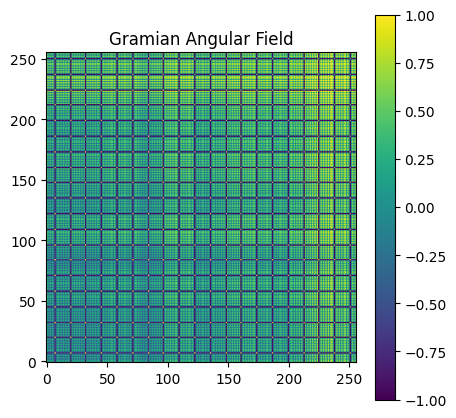

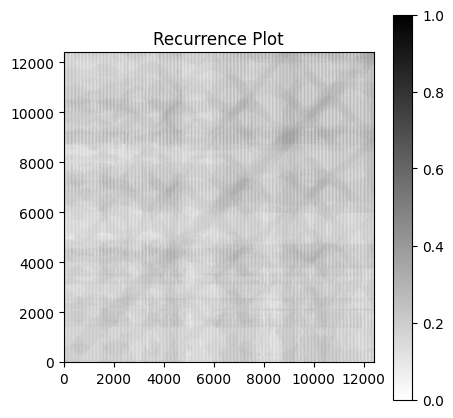

In [5]:
file_path = "data/PaHaW/PaHaW_public/00001/00001__1_1.svc"
X = load_svc_as_array(file_path)

sample = X.flatten()

ts = TimeSerieToImage(sample)

gaf_image = ts.to_gaf(image_size=256)
ts.plot(gaf_image, title="Gramian Angular Field")

rp_image = ts.to_recurrence_plot()
ts.plot(rp_image, title="Recurrence Plot", cmap="binary")

In [ ]:
import pandas as pd

from src.common.utils import build_pahaw_mapping, load_ruamel, set_determinism
from src.data.pahaw_dataset import PaHaWDataset
from src.model.vanilla_cnn import VanillaCNN
from src.run.model.run_image_classifier import RunImageClassifier
from src.visualization.vis_enum import PaHaWFeatures

In [4]:
general_cfg         = load_ruamel("config/general.yaml")
preproc_cfg         = load_ruamel("config/preprocessing/to_img.yaml")
exp_cfg             = load_ruamel("config/model/cnn_experiment_plot.yaml")
general_cfg         = load_ruamel("config/general.yaml")
preproc_general_cfg = load_ruamel("config/preprocessing/general.yaml")
model_general_cfg   = load_ruamel("config/model/general.yaml")

set_determinism(general_cfg["seed"])

df = pd.read_excel(general_cfg["csv_file"], engine="openpyxl")

feature_names = [feature.value for feature in PaHaWFeatures]
mapping = build_pahaw_mapping(
    general_cfg["base_dir"],
    feature_names=feature_names,
)

dataset = PaHaWDataset(
    mapping=mapping,
    df=df,
    visualizer=None,
)

excluded       = set(preproc_general_cfg["global"]["ids_to_exclude"])

valid_patients = [
    str(pid).zfill(5)
    for pid in dataset["ID"]
    if str(pid).zfill(5) not in excluded
]

In [ ]:
pipeline = RunImageClassifier(
    model_class=SmallResNetCNN,
    dataset=dataset,
    valid_patients=valid_patients,
    experiment_cfgs=exp_cfg["experiments"],
    model_cfg=model_general_cfg["model"],
    training_cfg=model_general_cfg["training"],
    seed=general_cfg["seed"],
)

pipeline.run()


[RunVanillaCNN] Starting experiment: vanilla_cnn_xy
  [RunVanillaCNN] Fold 1/5
  Epoch 01/75 | Train loss: 0.7205 | Val loss: 0.7218 | Val accuracy: 0.5333 | Val f1: 0.0000
  Epoch 02/75 | Train loss: 0.6911 | Val loss: 0.6955 | Val accuracy: 0.5333 | Val f1: 0.0000
  Epoch 03/75 | Train loss: 0.6705 | Val loss: 0.6900 | Val accuracy: 0.5333 | Val f1: 0.0000
  Epoch 04/75 | Train loss: 0.6959 | Val loss: 0.7100 | Val accuracy: 0.5333 | Val f1: 0.0000
  Epoch 05/75 | Train loss: 0.6716 | Val loss: 0.7390 | Val accuracy: 0.4667 | Val f1: 0.6279
  Epoch 06/75 | Train loss: 0.6478 | Val loss: 0.7617 | Val accuracy: 0.4833 | Val f1: 0.5811
  Epoch 07/75 | Train loss: 0.6324 | Val loss: 0.9232 | Val accuracy: 0.4500 | Val f1: 0.6071
  Epoch 08/75 | Train loss: 0.6195 | Val loss: 0.7758 | Val accuracy: 0.5417 | Val f1: 0.2466
  Epoch 09/75 | Train loss: 0.5950 | Val loss: 0.7366 | Val accuracy: 0.5000 | Val f1: 0.5588
  Epoch 10/75 | Train loss: 0.5401 | Val loss: 0.7790 | Val accuracy: 0.55

KeyboardInterrupt: 

In [ ]:
###Aggiungi al file di configurazione
## 1. boolean se salvare o meno i modelli addestrati
## 2. boolean se salvare o meno i risultati (accuracy, loss, ecc.)
## 3. path degli esperimenti (per salvare modelli e risultati in cartelle separate per ogni esperimento). Dove salvo 1 e 2
##    Salva tutto in cartelle di questa struttura: experiments/experiment_name/{modelname}_{results}

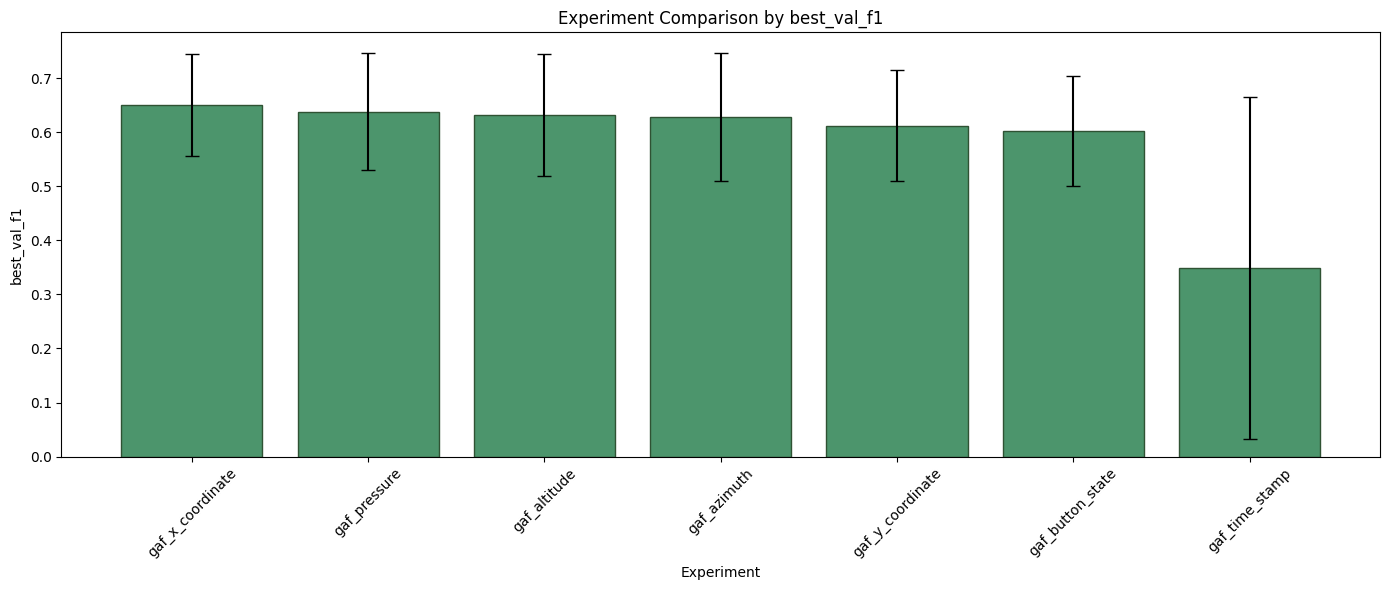

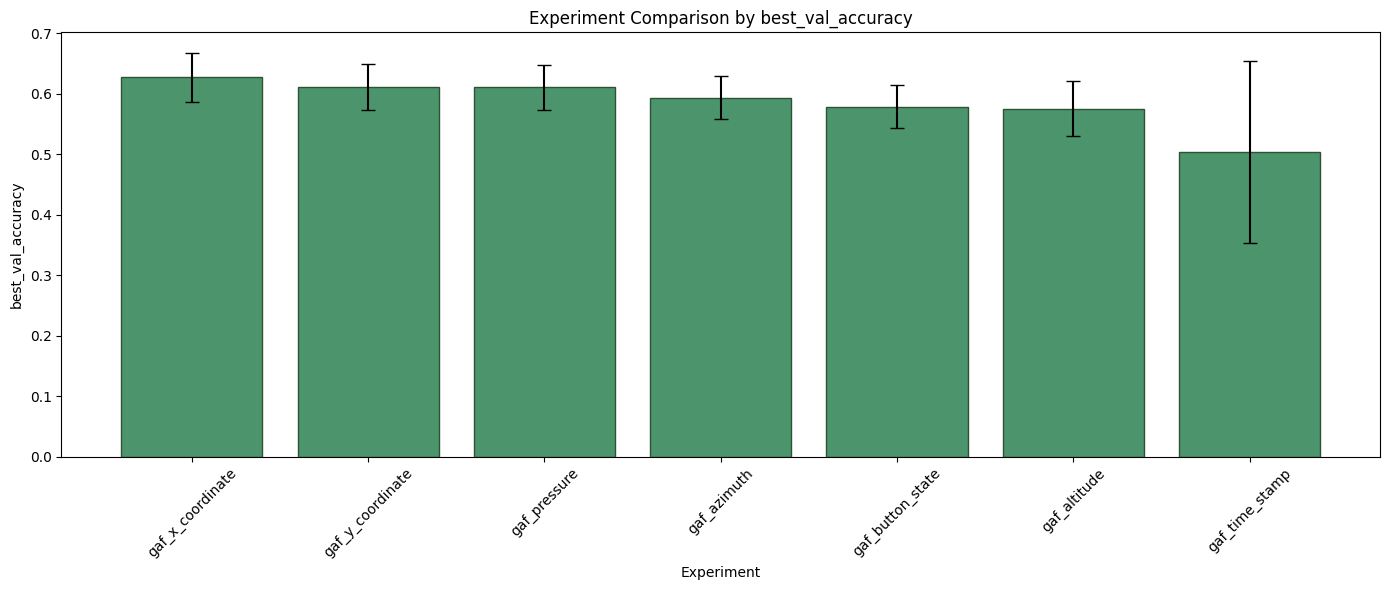

In [ ]:
import matplotlib.pyplot as plt
from src.common.experiment_results import (
    build_experiment_comparison,
    plot_experiment_comparison,
)

comparison_df = build_experiment_comparison("experiments")

gaf_rp_df = comparison_df[
    comparison_df["experiment"].str.contains(r"_gaf_|_rp_", regex=True)
].copy()

gaf_rp_df["experiment"] = (
    gaf_rp_df["experiment"]
    .str.replace("vanilla_cnn_", "", regex=False)
)

plot_experiment_comparison(gaf_rp_df, metric="best_val_f1", figsize=(14, 6))
plt.show()

plot_experiment_comparison(gaf_rp_df, metric="best_val_accuracy", figsize=(14, 6))
plt.show()

In [4]:
import pandas as pd

from src.common.utils import build_pahaw_mapping, load_ruamel
from src.data.pahaw_dataset import PaHaWDataset
from src.run.preprocess.run_preprocessing_to_image import RunPreprocessingToImage
from src.visualization.visualizer import Visualizer
from src.visualization.vis_enum import PaHaWFeatures

In [5]:
general_cfg = load_ruamel("config/general.yaml")
preproc_cfg = load_ruamel("config/preprocessing/to_img.yaml")

df = pd.read_excel(general_cfg["csv_file"], engine="openpyxl")

feature_names = [feature.value for feature in PaHaWFeatures]
mapping = build_pahaw_mapping(
    general_cfg["base_dir"],
    feature_names=feature_names,
)

ids_to_exclude = preproc_cfg["global"].get("ids_to_exclude", [])
valid_patients = [
    pid for pid in sorted(mapping.keys())
    if pid not in ids_to_exclude
]

dataset = PaHaWDataset(
    mapping=mapping,
    df=df,
    visualizer=Visualizer(),
)

In [ ]:
pipeline = RunPreprocessingToImage(
    dataset=dataset,
    experiments=preproc_cfg["experiments"],
    valid_patients=valid_patients,
    global_cfg=preproc_cfg["global"],
)

pipeline.run()

[PaHaW] Running experiment: xy_XCoor_YCoor
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_1.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_2.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_3.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_4.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_5.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_6.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_7.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00001_task_8.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00002_task_1.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00002_task_2.png...
Saving plot to data/PaHaW/PaHaW_processed/xy_XCoor_YCoor/patient_00002_task_3.png...
Saving plot to data/Pa

In [ ]:
import pandas as pd

from src.common.utils import build_pahaw_mapping, load_ruamel, set_determinism
from src.data.pahaw_dataset import PaHaWDataset
from src.model.small_resnet_cnn import SmallResNetCNN
from src.run.model.run_image_classifier import RunImageClassifier
from src.visualization.vis_enum import PaHaWFeatures

In [5]:
general_cfg = load_ruamel("config/general.yaml")
model_general_cfg = load_ruamel("config/model/general.yaml")
plot_exp_cfg = load_ruamel("config/model/cnn_experiment_plot.yaml")

set_determinism(general_cfg["seed"])

df = pd.read_excel(general_cfg["csv_file"], engine="openpyxl")

feature_names = [feature.value for feature in PaHaWFeatures]
mapping = build_pahaw_mapping(
    general_cfg["base_dir"],
    feature_names=feature_names,
)

valid_patients = sorted(mapping.keys())

dataset = PaHaWDataset(
    mapping=mapping,
    df=df,
    visualizer=None,
)

In [6]:
pipeline = RunImageClassifier(
    model_class=SmallResNetCNN,
    dataset=dataset,
    valid_patients=valid_patients,
    experiment_cfgs=plot_exp_cfg["experiments"],
    model_cfg=model_general_cfg["model"],
    training_cfg=model_general_cfg["training"],
    seed=general_cfg["seed"],
)

pipeline.run()


[RunImageClassifier] Starting experiment: vanilla_cnn_xy
  [RunImageClassifier] Fold 1/5


    [RunImageClassifier] Normalization stats mean=[0.9271902013897518] std=[0.1906998660837448]
  Epoch 01/75 | Train loss: 0.7325 | Val loss: 0.7264 | Val accuracy: 0.4500 | Val f1: 0.4211
  Epoch 02/75 | Train loss: 0.6908 | Val loss: 0.9066 | Val accuracy: 0.2667 | Val f1: 0.4211
  Epoch 03/75 | Train loss: 0.6727 | Val loss: 0.7397 | Val accuracy: 0.4000 | Val f1: 0.4194
  Epoch 04/75 | Train loss: 0.6780 | Val loss: 0.7133 | Val accuracy: 0.4750 | Val f1: 0.4324
  Epoch 05/75 | Train loss: 0.6748 | Val loss: 0.9602 | Val accuracy: 0.2833 | Val f1: 0.4267
  Epoch 06/75 | Train loss: 0.6851 | Val loss: 0.6546 | Val accuracy: 0.7250 | Val f1: 0.1951
  Epoch 07/75 | Train loss: 0.6752 | Val loss: 0.8229 | Val accuracy: 0.3000 | Val f1: 0.4247
  Epoch 08/75 | Train loss: 0.6702 | Val loss: 0.6941 | Val accuracy: 0.5417 | Val f1: 0.3820
  Epoch 09/75 | Train loss: 0.6700 | Val loss: 0.7855 | Val accuracy: 0.4000 | Val f1: 0.4545
  Epoch 10/75 | Train loss: 0.6621 | Val loss: 1.1099 | Va

In [4]:
import matplotlib.pyplot as plt

from src.common.experiment_results import (
    build_experiment_comparison,
    plot_experiment_comparison,
)

comparison_df = build_experiment_comparison("experiments")
comparison_df


,experiment,best_val_accuracy,best_val_f1,original_experiment,model_name,general_type_of_input,specific_type_of_input,best_val_accuracy_std,best_val_f1_std
0,small_resnet_cnn/plot/xyz_pressure,0.669020,0.684245,vanilla_cnn_xyz_pressure,small_resnet_cnn,plot,xyz_pressure,0.057396,0.099469
1,small_resnet_cnn/plot/xyz_button_state,0.642454,0.680064,vanilla_cnn_xyz_button_state,small_resnet_cnn,plot,xyz_button_state,0.048225,0.093787
2,small_resnet_cnn/plot/xyz_azimuth,0.635247,0.673142,vanilla_cnn_xyz_azimuth,small_resnet_cnn,plot,xyz_azimuth,0.078818,0.133765
3,small_resnet_cnn/plot/xy,0.644496,0.672795,vanilla_cnn_xy,small_resnet_cnn,plot,xy,0.067964,0.114885
4,small_resnet_cnn/plot/xyz_timestamp,0.629753,0.671311,vanilla_cnn_xyz_timestamp,small_resnet_cnn,plot,xyz_timestamp,0.077555,0.122155
5,small_resnet_cnn/gaf/altitude,0.664496,0.669803,vanilla_cnn_gaf_altitude,small_resnet_cnn,gaf,altitude,0.062238,0.123818
6,small_resnet_cnn/plot/xyz_altitude,0.639359,0.667804,vanilla_cnn_xyz_altitude,small_resnet_cnn,plot,xyz_altitude,0.061302,0.127269
7,small_resnet_cnn/gaf/x_coordinate,0.636969,0.666838,vanilla_cnn_gaf_x_coordinate,small_resnet_cnn,gaf,x_coordinate,0.084422,0.129373
8,small_resnet_cnn/gaf/y_coordinate,0.637592,0.664517,vanilla_cnn_gaf_y_coordinate,small_resnet_cnn,gaf,y_coordinate,0.047361,0.123852
9,small_resnet_cnn/gaf/pressure,0.603333,0.662028,vanilla_cnn_gaf_pressure,small_resnet_cnn,gaf,pressure,0.023274,0.117946


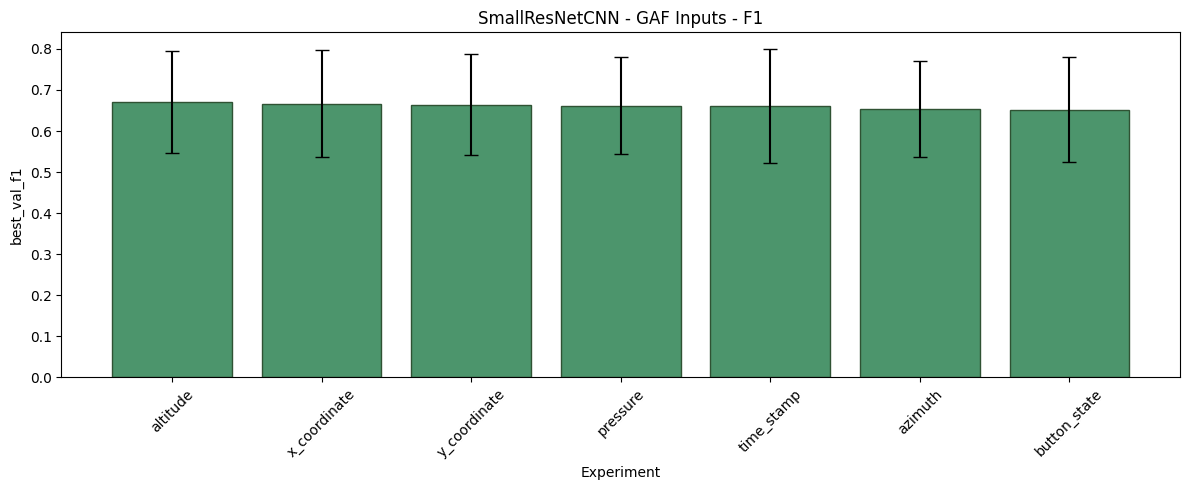

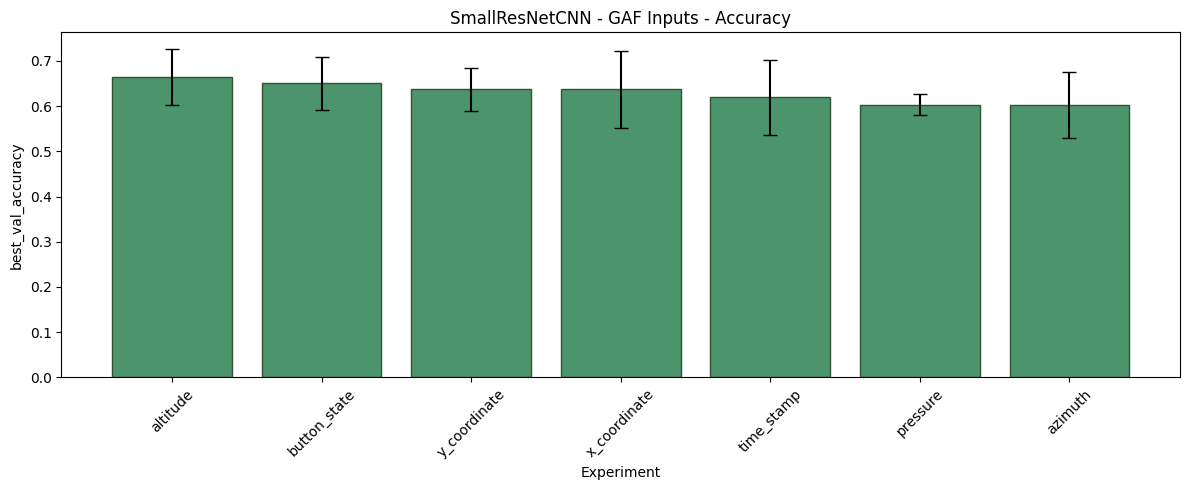

In [5]:
gaf_df = comparison_df[
    (comparison_df["model_name"] == "small_resnet_cnn") &
    (comparison_df["general_type_of_input"] == "gaf")
].copy()

plot_experiment_comparison(
    gaf_df,
    metric="best_val_f1",
    figsize=(12, 5),
    label_column="specific_type_of_input",
)
plt.title("SmallResNetCNN - GAF Inputs - F1")
plt.show()

plot_experiment_comparison(
    gaf_df,
    metric="best_val_accuracy",
    figsize=(12, 5),
    label_column="specific_type_of_input",
)
plt.title("SmallResNetCNN - GAF Inputs - Accuracy")
plt.show()


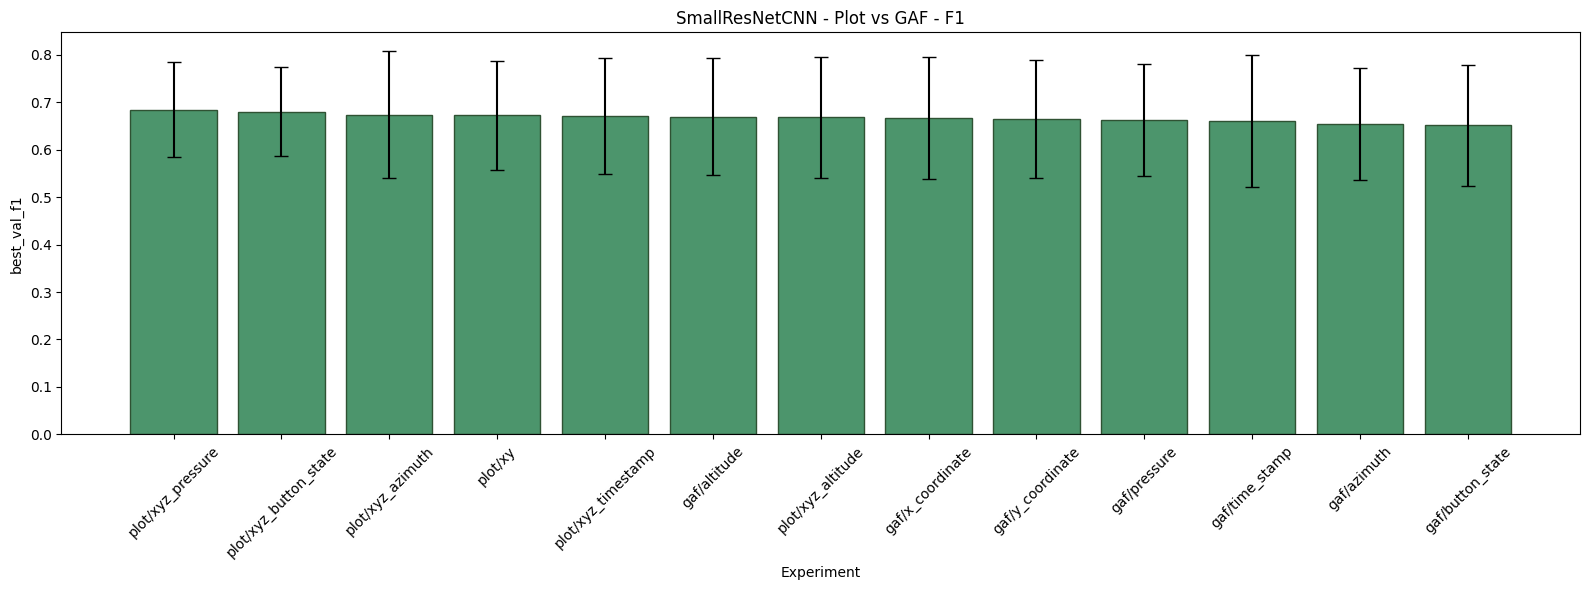

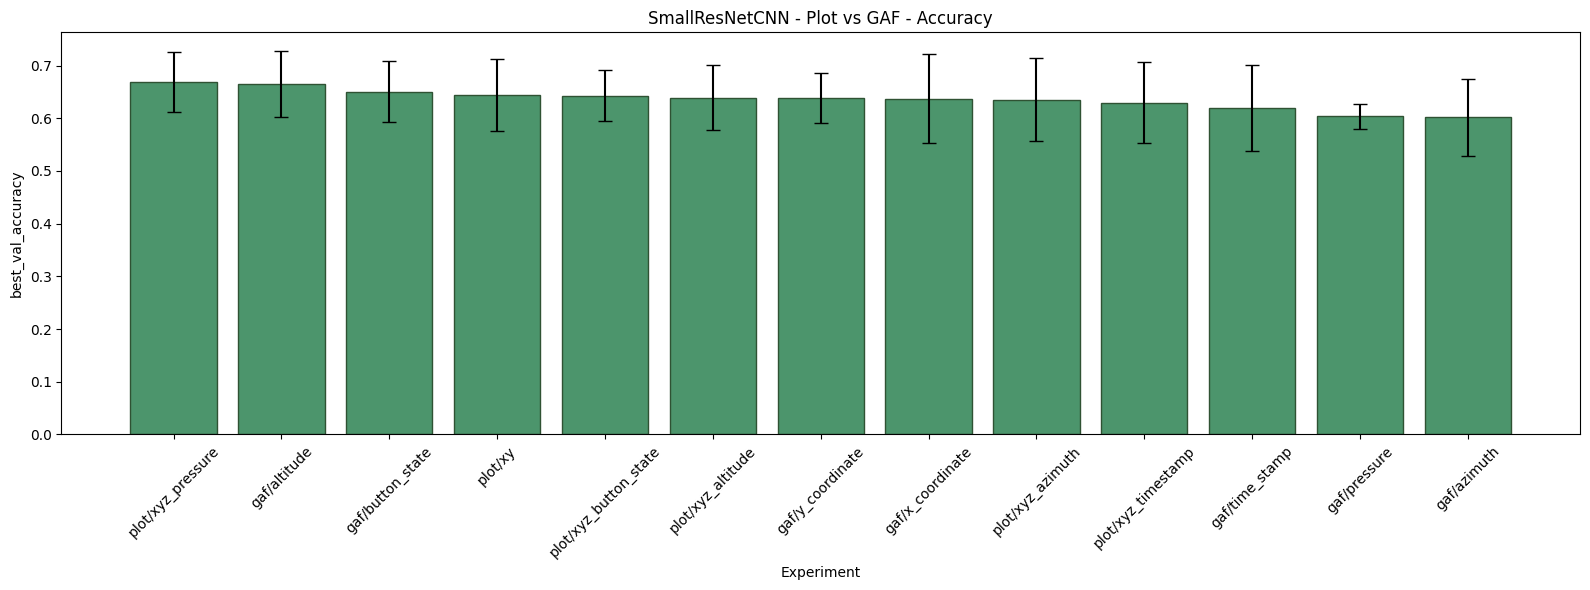

In [7]:
gaf_vs_plot_df = comparison_df[
    (comparison_df["model_name"] == "small_resnet_cnn") &
    (comparison_df["general_type_of_input"].isin(["plot", "gaf"]))
].copy()

gaf_vs_plot_df["label"] = (
    gaf_vs_plot_df["general_type_of_input"] + "/" +
    gaf_vs_plot_df["specific_type_of_input"]
)

plot_experiment_comparison(
    gaf_vs_plot_df,
    metric="best_val_f1",
    figsize=(16, 6),
    label_column="label",
)
plt.title("SmallResNetCNN - Plot vs GAF - F1")
plt.show()

plot_experiment_comparison(
    gaf_vs_plot_df,
    metric="best_val_accuracy",
    figsize=(16, 6),
    label_column="label",
)
plt.title("SmallResNetCNN - Plot vs GAF - Accuracy")
plt.show()



In [4]:
import matplotlib.pyplot as plt

from src.common.experiment_results import (
    build_experiment_comparison,
    plot_experiment_comparison,
)

comparison_df = build_experiment_comparison("experiments")
comparison_df


,experiment,best_val_accuracy,best_val_f1,original_experiment,model_name,general_type_of_input,specific_type_of_input,best_val_accuracy_std,best_val_f1_std
0,mamba_sequence_classifier/raw_sequence/all_fea...,0.776190,0.772656,train_on_word_nepopadnout_validate_on_word_nep...,mamba_sequence_classifier,raw_sequence,all_features,0.096068,0.100478
1,mamba_sequence_classifier/raw_sequence/all_fea...,0.762857,0.762046,train_on_archimedes_spiral_validate_on_archime...,mamba_sequence_classifier,raw_sequence,all_features,0.067461,0.066930
2,mamba_sequence_classifier/raw_sequence/all_fea...,0.707619,0.751169,train_on_cursive_letter_l_validate_on_cursive_...,mamba_sequence_classifier,raw_sequence,all_features,0.093411,0.056116
3,mamba_sequence_classifier/raw_sequence/all_fea...,0.736190,0.741329,train_on_trigram_les_validate_on_trigram_les,mamba_sequence_classifier,raw_sequence,all_features,0.075036,0.057336
4,mamba_sequence_classifier/raw_sequence/all_fea...,0.761905,0.741176,train_on_word_lektorka_validate_on_word_lektorka,mamba_sequence_classifier,raw_sequence,all_features,0.108640,0.120083
5,mamba_sequence_classifier/raw_sequence/all_fea...,0.752381,0.734547,train_on_sentence_tramvaj_dnes_uz_nepojede_val...,mamba_sequence_classifier,raw_sequence,all_features,0.095891,0.112651
6,mamba_sequence_classifier/raw_sequence/all_fea...,0.734286,0.725900,train_on_word_porovnat_validate_on_word_porovnat,mamba_sequence_classifier,raw_sequence,all_features,0.097729,0.100582
7,mamba_sequence_classifier/raw_sequence/all_fea...,0.693333,0.692670,train_on_bigram_le_validate_on_bigram_le,mamba_sequence_classifier,raw_sequence,all_features,0.120872,0.096242
8,small_resnet_cnn/plot/xyz_pressure,0.669020,0.684245,vanilla_cnn_xyz_pressure,small_resnet_cnn,plot,xyz_pressure,0.057396,0.099469
9,small_resnet_cnn/plot/xyz_button_state,0.642454,0.680064,vanilla_cnn_xyz_button_state,small_resnet_cnn,plot,xyz_button_state,0.048225,0.093787
